In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

SEED = 42

df = fetch_openml(name='adult', version=2, as_frame=True).frame
y = (df['class'] == '>50K').astype(int)   # again, 1 = True (earns >50K), 0 = <=50K
x = df.drop(columns=['class'])

numeric_cols = x.select_dtypes(include='number').columns.tolist()
categorical_cols = x.select_dtypes(exclude='number').columns.tolist()
x[categorical_cols] = x[categorical_cols].astype(object)  # avoids imputer problems with the category dtype

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=SEED)
print(x_train.shape, x_test.shape)
print(y_train.mean(), y_test.mean())  # both should be aprox 0.239

(39073, 14) (9769, 14)
0.23927008420136667 0.23932848807452145


In [22]:
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),])
categorical_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_cols),
    ('cat', categorical_pipe, categorical_cols)], sparse_threshold=0)

Data leakage happens when information from the test data influences training, so the test score looks better than it will be on new data. For example, if I computed the median or the mean for imputation and scaling on the whole dataset before splitting, the training process would already “know” something about the test rows. In my code I split first, and the preprocessing is inside a Pipeline, so fit only sees training data. During cross-validation the pipeline is refitted inside each fold, so the validation part of each fold is never used to compute medians, means or categories.

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

def evaluate(name, model):
    pipe = Pipeline([('prep', preprocessor), ('clf', model)]) # preprocessing fitted only on the training folds
    res = cross_validate(pipe, x_train, y_train, cv=cv, scoring=scoring)
    row = {m: res[f'test_{m}'].mean() for m in scoring}
    row['model'] = name
    return row

baseline_results = pd.DataFrame([
    evaluate('Dummy (majority)', DummyClassifier(strategy='most_frequent')),
    evaluate('Logistic regression', LogisticRegression(max_iter=1000, random_state=SEED)),
]).set_index('model').round(3)

baseline_results

C:\Users\Diana\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Diana\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Diana\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metri

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Dummy (majority),0.761,0.000,0.000,0.000,0.500
Logistic regression,0.851,0.732,0.597,0.658,0.906


Why accuracy alone is weak:
About 76% of the people earn <=50K, so a model that always predicts <=50K already gets 76% accuracy without learning anything. Accuracy also hides how the model does on the minority class (>50K), which is the group we care about, so we need recall, F1 and ROC AUC as well.

In [24]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    'Logistic regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'Random forest': RandomForestClassifier(random_state=SEED, n_jobs=-1), #n_jobs=-1 lets the forest use all CPU cores
    'Gradient boosting': HistGradientBoostingClassifier(random_state=SEED),
}
rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', model)])
    res = cross_validate(pipe, x_train, y_train, cv=cv, scoring=['roc_auc', 'f1'])
    rows.append({
        'model': name,
        'ROC AUC mean': res['test_roc_auc'].mean(),
        'ROC AUC std': res['test_roc_auc'].std(),
        'F1 mean': res['test_f1'].mean(),
        'F1 std': res['test_f1'].std(),})

cv_results = pd.DataFrame(rows).set_index('model').round(3)
cv_results

,ROC AUC mean,ROC AUC std,F1 mean,F1 std
model,,,,
Logistic regression,0.906,0.004,0.658,0.010
Random forest,0.901,0.004,0.665,0.009
Gradient boosting,0.928,0.002,0.708,0.008


Gradient boosting scored highest on both metrics, with a gap of several standard deviations over the other two, so I chose it for tuning.

In [27]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', HistGradientBoostingClassifier(random_state=SEED))])
# the same "cleaning, then model" pipeline. tuning happens on the whole pipeline, so no leakage

param_grid = {
    'clf__learning_rate': [0.05, 0.1],
    'clf__max_depth': [3, None]}
# 'clf__' means the setting belongs to the step named clf. 2*2 = 4 combos

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='roc_auc', n_jobs=1)
# cv=cv reuses 5-fold rule. scoring='roc_auc' is the metric that picks the winner
# 4 combinations * 5 folds = 20 fits, so it'll take a minute

grid.fit(x_train, y_train) # training only

print(grid.best_params_)
print(round(grid.best_score_, 3))

tuning_results = (pd.DataFrame(grid.cv_results_)
                  [['param_clf__learning_rate', 'param_clf__max_depth', 'mean_test_score', 'std_test_score']]
                  .sort_values('mean_test_score', ascending=False)
                  .round(4))
tuning_results

{'clf__learning_rate': 0.1, 'clf__max_depth': None}
0.928


,param_clf__learning_rate,param_clf__max_depth,mean_test_score,std_test_score
3,0.10,None,0.9276,0.0024
1,0.05,None,0.9262,0.0024
2,0.10,3,0.9199,0.0032
0,0.05,3,0.9130,0.0033


I tried learning_rate in {0.05, 0.1} and max_depth in {3, None}. The best combination (0.1, None) matched the library defaults, with CV ROC AUC 0.928, so tuning gave no measurable gain. Limiting depth to 3 hurt. That’s 4 combinations * 5 folds, and it covers “at least two hyperparameters”.

{'accuracy': 0.875, 'precision': 0.785, 'recall': 0.66, 'f1': 0.717, 'roc_auc': 0.929}


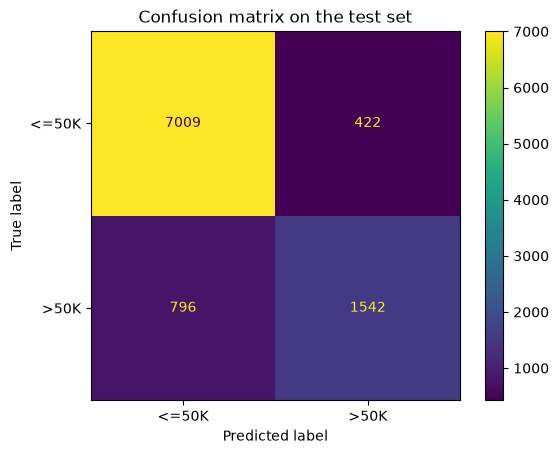

In [29]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

best_model = grid.best_estimator_

y_pred = best_model.predict(x_test) # 0 or 1 for each test person. pipeline cleans x_test with the statistics learned from training
y_proba = best_model.predict_proba(x_test)[:, 1] # models probability of ">50K" for each person. ROC AUC does not use 0/1

test_scores = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall': recall_score(y_test, y_pred),
    'f1': f1_score(y_test, y_pred),
    'roc_auc': roc_auc_score(y_test, y_proba)}

print({k: round(v, 3) for k, v in test_scores.items()})

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K']).plot()
plt.title('Confusion matrix on the test set')
plt.show()